In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")
df = pd.read_csv("cleaned_dataset.csv")

In [2]:
features = [
    'Average Cost for two',
    'Price range',
    'Aggregate rating',
    'Votes'
]

X = df[features].copy()

In [6]:
print(X.isnull().sum())
print("\n",(X < 0).sum())

Average Cost for two    0
Price range             0
Aggregate rating        0
Votes                   0
dtype: int64

 Average Cost for two    0
Price range             0
Aggregate rating        0
Votes                   0
dtype: int64


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [8]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

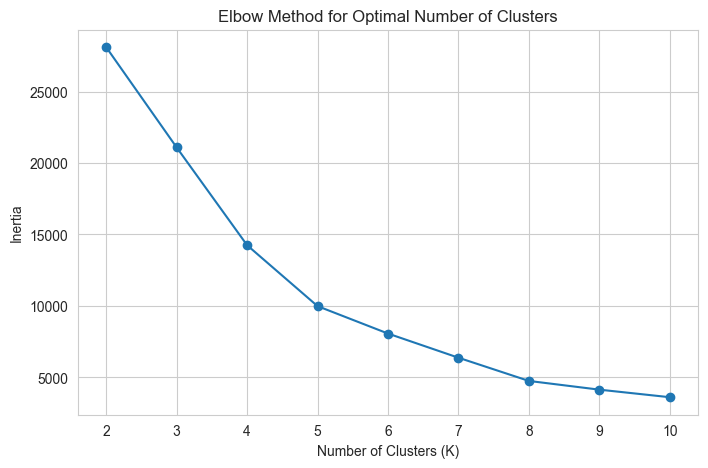

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.show()

In [11]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: {score:.4f}")

K=2: 0.3970
K=3: 0.5642
K=4: 0.5726
K=5: 0.5895
K=6: 0.5897
K=7: 0.5996
K=8: 0.6127
K=9: 0.6190
K=10: 0.6526


In [12]:
optimal_k = 5

In [13]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

In [14]:
df['Cluster'].value_counts().sort_index()

Cluster
0    5378
1    1812
2    2137
3      15
4     209
Name: count, dtype: int64

In [11]:
cluster_summary = df.groupby('Cluster')[features].mean()

cluster_summary.round(2)

,Average Cost for two,Price range,Aggregate rating,Votes
Cluster,,,,
0,428.45,1.49,3.29,93.26
1,1565.45,3.29,3.75,274.13
2,330.48,1.22,0.00,0.87
3,346666.67,3.00,4.39,869.33
4,1945.43,2.87,4.22,2322.96


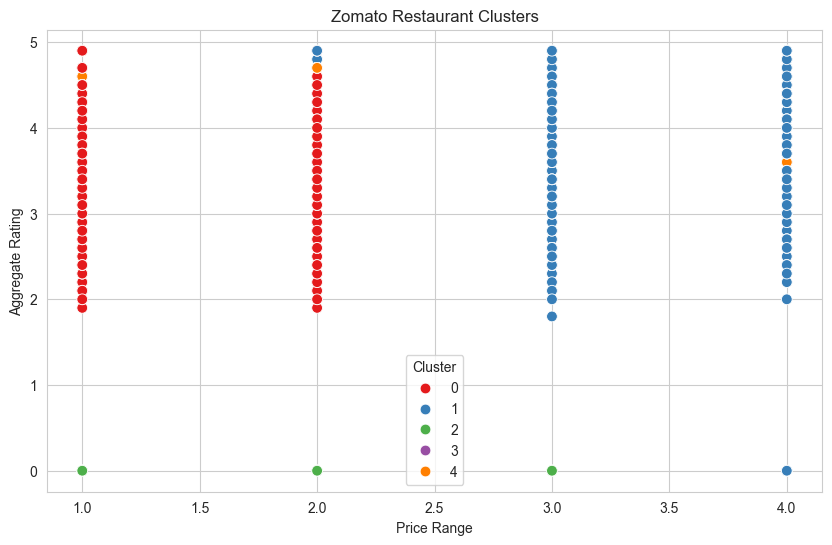

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Price range',
    y='Aggregate rating',
    hue='Cluster',
    palette='Set1',
    s=60
)

plt.title('Zomato Restaurant Clusters')
plt.xlabel('Price Range')
plt.ylabel('Aggregate Rating')
plt.legend(title='Cluster')

plt.show()

In [15]:
df.to_csv(
    "Zomato_Clustered.csv",
    index=False
)

In [16]:
cluster_summary = df.groupby('Cluster')[features].mean()

cluster_summary.round(2)

,Average Cost for two,Price range,Aggregate rating,Votes
Cluster,,,,
0,428.45,1.49,3.29,93.26
1,1565.45,3.29,3.75,274.13
2,330.48,1.22,0.00,0.87
3,346666.67,3.00,4.39,869.33
4,1945.43,2.87,4.22,2322.96
